# Nbook that links the detected/segmented features 
- links "cell_features_combined" from 27_ and 28_ (OBS and ICON monthly datasets) 
- for ICON and OBS for June and December Data
- some plotting
- input: cell_features_combined
- output: linking/raw

# Import packages

In [1]:
import warnings

# ignore general categories
for cat in [FutureWarning, RuntimeWarning, UserWarning]:
    warnings.filterwarnings("ignore", category=cat)

# ignore specific repeated messages
for msg in [
    "pyproj unable to set PROJ database path",
    "As of v1.6.0, segmentation with time length 1",
    "Using DEFAULT_SPHERICAL_EARTH_RADIUS"
]:
    warnings.filterwarnings("ignore", message=msg)


import numpy as np
import xarray as xr
import os
import pandas as pd

from pathlib import Path

# Import tobac itself:
import tobac
import tobac.utils

print("using tobac version", str(tobac.__version__))

import iris

# some eval plotting
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import seaborn as sns

import h5py
import sys

import glob

# import use_tobac

sys.path.append("../tools")
from defs_application import bad_timesteps
import plots_mapping as pm

using tobac version 1.6.3


# arguments

In [3]:
model = "OBS"
timeperiod = "DECEMBER"

#inputdir = Path("../output/apply/apply_ICON_with_mask/anvil_detectthres225_seg241_cell_detectthres10_seg10/cell_features_combined")
if model == "OBS":
    inputdir = Path(f"../output/apply_seg/apply_{model}/{timeperiod}/cell_features_combined")
elif model == "ICON":
    inputdir = Path(f"../output/apply_seg/apply_{model}/{timeperiod}/cell_features_combined") # link to folder with feature env data
if timeperiod == "FULL": 
    inputdir = Path(f"../output/apply_seg/apply_{model}/{timeperiod}/cell_features_combined_envfeatures")
saveoutputs = True

savedir = Path(f"../output/linking/raw")
# create main directory
savedir.mkdir(parents=True, exist_ok=True)


plotsdir = Path(f"../output/linking/bsp_plots")

plotsdir.mkdir(parents=True, exist_ok=True)


# import feature tables

In [4]:
files = sorted(glob.glob(f'{inputdir}/*.h5'))
df = []
for file in files:
    data = pd.read_hdf(file, key='table')  
    print(file)
    data = data.reset_index(drop=True)
    df.append(data)

features = pd.concat(df, ignore_index=True) 

# fix corrupted time column from HDF5 precision issue, use timestr as ground truth
features['time'] = pd.to_datetime(features['timestr'])
features['time'] = features['time'].astype('datetime64[ns]')
# reset index
features = features.sort_values('time').reset_index(drop=True)  # sort here


# filter 5 bad days
features = features[~features['time'].isin(bad_timesteps)].reset_index(drop=True)


# rename columns so tobac can identify them
features = features.rename(columns={"hdim_1_cell": "hdim_1", "hdim_2_cell": "hdim_2"})
features = features.rename(columns={"longitude_cell": "longitude", "latitude_cell": "latitude"})
features = features.rename(columns={"feature_cell": "feature"})

# frame number was deleted by individual detection
full_time_grid = pd.date_range(start=features['time'].min(),end=features['time'].max(),freq='3h').astype('datetime64[ns]')
time_to_frame = {t: i for i, t in enumerate(full_time_grid)}
features['frame'] = features['time'].map(time_to_frame)

#print(features[['time', 'frame']].drop_duplicates().sort_values('frame'))
features

../output/apply_seg/apply_OBS/DECEMBER/cell_features_combined/cell_features_combined_anvil_detectthres225_seg241_cell_detectthres10_seg10_2023-12-01-0000.h5
../output/apply_seg/apply_OBS/DECEMBER/cell_features_combined/cell_features_combined_anvil_detectthres225_seg241_cell_detectthres10_seg10_2023-12-01-0300.h5
../output/apply_seg/apply_OBS/DECEMBER/cell_features_combined/cell_features_combined_anvil_detectthres225_seg241_cell_detectthres10_seg10_2023-12-01-0600.h5
../output/apply_seg/apply_OBS/DECEMBER/cell_features_combined/cell_features_combined_anvil_detectthres225_seg241_cell_detectthres10_seg10_2023-12-01-0900.h5
../output/apply_seg/apply_OBS/DECEMBER/cell_features_combined/cell_features_combined_anvil_detectthres225_seg241_cell_detectthres10_seg10_2023-12-01-1200.h5
../output/apply_seg/apply_OBS/DECEMBER/cell_features_combined/cell_features_combined_anvil_detectthres225_seg241_cell_detectthres10_seg10_2023-12-01-1500.h5
../output/apply_seg/apply_OBS/DECEMBER/cell_features_combi

,frame,idx_cell,hdim_1,hdim_2,num_cell,threshold_value_cell,feature,time,timestr,latitude,...,mean_iwp_anvil,total_iwp_anvil,max_iwp,min_tb,area_anvil,d_eq_anvil,mean_precip_anvil,total_precip_anvil,max_precip_anvil,total_dtiwp_anvil
0,0,1,28.641074,14.723263,6,10,1,2023-12-01 00:00:00,2023-12-01 00:00:00,-27.085892,...,1.901556,2646.966309,7.677646,214.875351,1.532093e+11,441.669746,2.281135,3175.339844,14.169999,264.750122
1,0,141,313.000000,2878.000000,1,10,141,2023-12-01 00:00:00,2023-12-01 00:00:00,1.350000,...,1.732014,1972.764160,7.500590,198.046539,1.405175e+11,422.980373,2.775500,3161.294922,18.580000,272.841064
2,0,142,315.230947,2775.579561,6,10,142,2023-12-01 00:00:00,2023-12-01 00:00:00,1.573095,...,1.901858,545.833252,6.591937,207.947235,3.542442e+10,212.376489,1.923287,551.983337,16.928333,128.341583
3,0,143,316.371591,1680.851407,5,10,143,2023-12-01 00:00:00,2023-12-01 00:00:00,1.687159,...,3.570670,399.915039,6.067162,218.895081,1.382824e+10,132.690080,5.481429,613.919983,16.466667,111.930298
4,0,144,318.000000,1836.000000,1,10,144,2023-12-01 00:00:00,2023-12-01 00:00:00,1.850000,...,3.242593,823.618713,6.667356,210.449738,3.135656e+10,199.810943,4.228426,1074.020020,14.915000,222.031952
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35508,247,62,241.574095,3201.838917,11,10,62,2023-12-31 21:00:00,2023-12-31 21:00:00,-5.792590,...,3.209751,3405.545898,12.348382,195.099976,1.303394e+11,407.373638,1.895711,2011.349854,16.448332,616.393005
35509,247,65,252.000000,3209.000000,1,10,65,2023-12-31 21:00:00,2023-12-31 21:00:00,-4.750000,...,3.209751,3405.545898,12.348382,195.099976,1.303394e+11,407.373638,1.895711,2011.349854,16.448332,616.393005
35510,247,66,252.762768,3211.762768,2,10,66,2023-12-31 21:00:00,2023-12-31 21:00:00,-4.673723,...,3.209751,3405.545898,12.348382,195.099976,1.303394e+11,407.373638,1.895711,2011.349854,16.448332,616.393005
35511,247,57,228.641664,3180.427921,25,10,57,2023-12-31 21:00:00,2023-12-31 21:00:00,-7.085833,...,3.522507,796.086670,10.967091,194.738968,2.769324e+10,187.776816,3.662603,827.748291,34.036663,213.920776


In [5]:
print(np.unique(features["time"]== "2023-06-05 21:00:00"))
np.unique(features["frame"])
# => date is not present and frame 39 is also missing, top, checked that timestamp are actually missing and frame number are correct

[False]


array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  51,  52,  53,
        54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,  66,
        67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,  79,
        80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,  92,
        93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104, 105,
       106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118,
       119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131,
       132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144,
       145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157,
       158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170,
       171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 18

# Linking

In [6]:
dxy = 11119.492664455873
dt = 10800 #s = 3h*3600
vmax = 20
stubs =1

In [7]:
# # find a v_max value
# v_max = 20
# search_range = v_max * dt / dxy
# print(search_range) 
# v_max *dt

In [8]:
Tracks = tobac.linking_trackpy(
    features, # detected features
    None, # needs to be none (input field, not used in tobac version)
    dt=dt, dxy=dxy, 
    v_max=vmax,
    method_linking="predict", 
    stubs=stubs,   
    adaptive_stop = 0.2,
    adaptive_step  = 0.95,
    PBC_flag="hdim_2", min_h2=0, max_h2=3600) # 3600 is lon dims in imerg grid


Frame 247: 135 trajectories present.


wenn 20 m/s = 51867
wenn 50 m/s = 40164
wenn 100 m/s = 39550

=> nun frage was richtig ist....

# merge and splits

In [9]:
merges_splits = tobac.merge_split.merge_split_MEST(
    Tracks, dxy=dxy, distance=dxy, frame_len=0, # 1 timestamp away
    PBC_flag="hdim_2", min_h2=0, max_h2=3599
)
Tracks["track"] = merges_splits.feature_parent_track_id.data.astype(np.int64)

track_start_time = Tracks.groupby("track").time.min()
Tracks["time_track"] = Tracks.time - track_start_time[Tracks.track].to_numpy()

In [10]:
merges_splits.cell_ends_with_merge.sum(), merges_splits.cell_starts_with_split.sum()

(<xarray.DataArray 'cell_ends_with_merge' ()> Size: 8B
 array(91),
 <xarray.DataArray 'cell_starts_with_split' ()> Size: 8B
 array(91))

In [11]:
merges_splits.track_child_cell_count.max(),Tracks.track.max(),Tracks.cell.max()

(<xarray.DataArray 'track_child_cell_count' ()> Size: 8B
 array(3),
 17747,
 17838)

In [12]:
Tracks.columns

Index(['frame', 'idx_cell', 'hdim_1', 'hdim_2', 'num_cell',
       'threshold_value_cell', 'feature', 'time', 'timestr', 'latitude',
       'longitude', 'ncells_cell', 'mean_precip_cell', 'total_precip_cell',
       'max_precip_cell', 'area_cell', 'd_eq_cell', 'total_dtiwp_cell',
       'mean_iwp_cell', 'total_iwp_cell', 'idx_anvil', 'hdim_1_anvil',
       'hdim_2_anvil', 'num_anvil', 'threshold_value_anvil', 'feature_anvil',
       'latitude_anvil', 'longitude_anvil', 'ncells_anvil', 'mean_iwp_anvil',
       'total_iwp_anvil', 'max_iwp', 'min_tb', 'area_anvil', 'd_eq_anvil',
       'mean_precip_anvil', 'total_precip_anvil', 'max_precip_anvil',
       'total_dtiwp_anvil', 'cell', 'time_cell', 'track', 'time_track'],
      dtype='object')

## add velo 

In [13]:
Tracks = tobac.calculate_velocity(Tracks, method_distance="latlon")
Tracks["v"].describe()

count    17668.000000
mean         9.988786
std          7.208460
min          0.000000
25%          4.569069
50%          8.433035
75%         13.722122
max         61.396440
Name: v, dtype: float64

In [14]:
print(Tracks[Tracks['cell']==398][['frame','time','latitude','longitude']])
print(Tracks[Tracks['cell']==450][['frame','time','latitude','longitude']])

     frame                time  latitude  longitude
647      3 2023-12-01 09:00:00  0.128775  -4.087175
756      4 2023-12-01 12:00:00 -0.047259  -5.361748
948      5 2023-12-01 15:00:00 -0.353031  -5.748617
     frame                time  latitude   longitude
723      4 2023-12-01 12:00:00  2.537996  166.367533


In [15]:
print(dxy, dt, vmax)
print(vmax * dt / dxy)  # implied max allowed displacement in grid cells per frame

11119.492664455873 10800 20
19.42534668784458


# save selected Tracks

In [16]:
if saveoutputs: 
    # save features
    Tracks.to_hdf(
        os.path.join(savedir, f"all_tracks_{model}_{timeperiod}.h5"),
        key='table', mode='w'
    )


/tmp/ipykernel_4183810/1558082759.py:3: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block3_values] [items->Index(['timestr', 'total_dtiwp_cell', 'mean_iwp_cell', 'total_iwp_cell',
       'total_dtiwp_anvil'],
      dtype='object')]

  Tracks.to_hdf(


# some evaluations

In [17]:
#Tracks_20 = Tracks

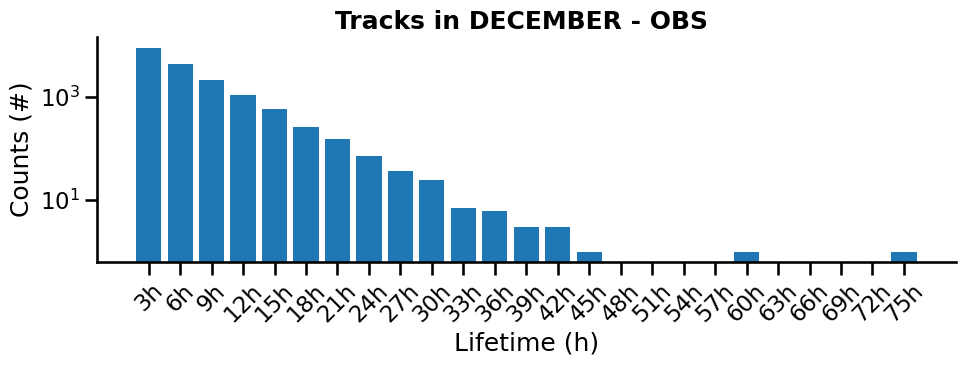

In [18]:
sns.set_context("talk")
# compute lifetime per cell in hours
cell_lifetimes = (Tracks[Tracks['track'] >= 0].groupby('track')['time'].nunique() * dt / 3600)
dt_h = dt / 3600
max_lifetime = cell_lifetimes.max()

# use half-open bins with small epsilon to ensure e.g. 3.0 falls in [3, 6)
bin_edges = np.arange(dt_h - 0.01, max_lifetime + dt_h, dt_h)
counts, _ = np.histogram(cell_lifetimes, bins=bin_edges)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(bin_edges[:-1] + 0.01,  counts, width=dt_h * 0.8, align='center')

ax.set_xticks(bin_edges[:-1] + 0.01)
ax.set_xticklabels([f'{int(round(h))}h' for h in np.arange(dt_h, max_lifetime + dt_h, dt_h)], rotation=45)
ax.set_xlabel('Lifetime (h)')
ax.set_ylabel('Counts (#)')
ax.set_yscale("log")
ax.set_title(f"Tracks in {timeperiod} - {model} ", fontweight = "bold")
sns.despine()
plt.tight_layout()
#plt.savefig(os.path.join(plotsdir, f"lifetimehistogram_raw_tracks_{model}_{timeperiod}.pdf"))
plt.show()

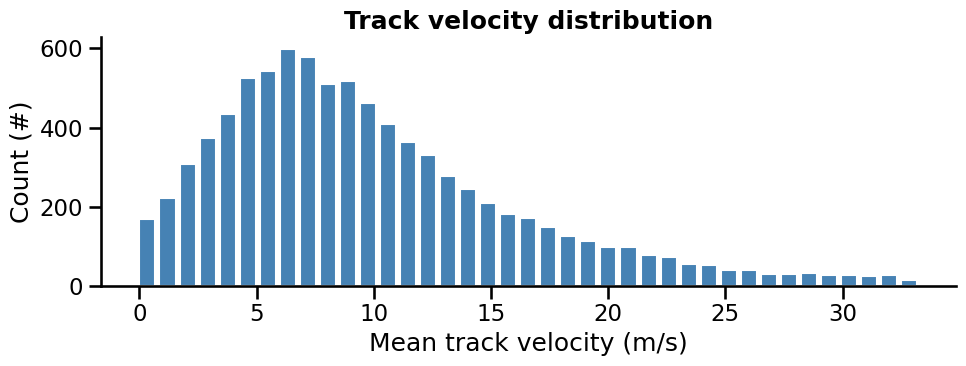

In [19]:

velocities = Tracks[Tracks['track'] >= 0].groupby('track')['v'].mean()  # mean velocity per cell

v_max_plot = velocities.quantile(0.99)  # avoid extreme outliers stretching the axis
bin_edges = np.linspace(0, v_max_plot, 40)

counts, _ = np.histogram(velocities.dropna(), bins=bin_edges)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(
    bin_edges[:-1],
    counts,
    width=np.diff(bin_edges) * 0.8,
    align='edge',
    color='steelblue',
    edgecolor='white',
)
ax.set_xlabel('Mean track velocity (m/s)')
ax.set_ylabel('Count (#)')
#ax.set_yscale('log')
ax.set_title('Track velocity distribution', fontweight = "bold")
sns.despine()
plt.tight_layout()
plt.show()

## general overview

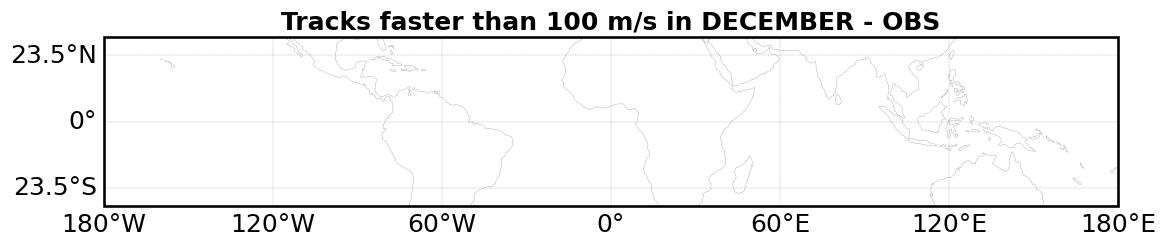

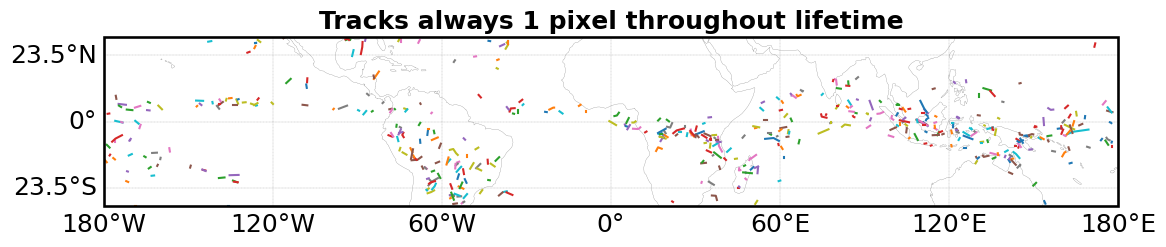

In [20]:
# cells whose mean velocity is exceeding threhsold
vmean = Tracks.groupby('track')["v"].mean()
v_thresh = 100 # m/s 
selected_cells = vmean[vmean > v_thresh].index
selected = Tracks[Tracks['track'].isin(selected_cells)]

fig, ax, gl = pm.domain_plot_cells(selected, 'track', title = f"Tracks faster than {v_thresh} m/s in {timeperiod} - {model}")
if vmax == 100:
    fig.savefig(os.path.join(plotsdir,f"maps_tracks_faster_than_{v_thresh}_for_vmax{vmax}_{model}_{timeperiod}.pdf"))

# always max 1 
cells_always_1px_ids = Tracks.groupby('track')["num_cell"].max()
cells_always_1px_ids = cells_always_1px_ids[cells_always_1px_ids == 1].index

cells_always_1px = Tracks[Tracks['track'].isin(cells_always_1px_ids)]
fig, ax, gl = pm.domain_plot_cells(cells_always_1px,'track', title="Tracks always 1 pixel throughout lifetime")
